# Clean PCI calculation and relation to `SAXS_PCI_Pointing_Div`

This notebook calculates **propagation-based phase-contrast imaging (PCI)**. It is not a SAXS far-field calculation. The workflow has three explicit stages:

1. generate the divergent Gaussian incident field $E_0(x,y)$ at the wire;
2. apply the Cu wire's thin-sample absorption and phase transmission $T(x,y)$;
3. propagate the complex exit field to the PCI detector with the exact angular-spectrum transfer function.

The model is

$$E_{\mathrm{exit}} = E_0\,\exp[-t/(2L_{\mathrm{att}})]\,\exp[-ik\delta t],$$

$$E_{\mathrm{det}} = \mathcal F^{-1}\!\left[\mathcal F\{E_{\mathrm{exit}}\}e^{ik_z z}\right], \qquad k_z=\sqrt{k^2-k_x^2-k_y^2}, \qquad I_{\mathrm{det}}=|E_{\mathrm{det}}|^2.$$

The source and target deliberately match the corresponding stages of `SAXS_PCI_Pointing_Div`: 8.2 keV photons, the smaller divergent Gaussian-waist solution, the absolute internal field scale from `PCI.gaussian_XFEL`, and a 5 micrometre-radius `PCI.Cu` wire projected with 20 nm voxels. The active clean configuration gives a 7.5 micrometre target-plane FWHM.

The detector workflow is intentionally different from the active legacy notebook. This clean PCI design uses a 4096 by 4096 fixed 8 nm grid and angular-spectrum propagation over a 6.31 m sample-to-detector distance. `SAXS_PCI_Pointing_Div` uses the `PCI.py` rescaled-grid Fresnel FFT for its SAXS detector and reconstructs a separate PCI image with LightPipes. Therefore the notebooks share the incident-beam and wire physics, but their detector propagation and outputs are not numerically interchangeable.

In [1]:
from dataclasses import dataclass
from pathlib import Path
from PIL import Image
import sys
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import make_interp_spline
from scipy.ndimage import shift as nd_shift

ROOT = Path.cwd()
SAXS_DIR = ROOT / "SAXS_asymmetry" if (ROOT / "SAXS_asymmetry" / "PCI.py").exists() else ROOT
INPUT_DIR = SAXS_DIR / "inputs"
OUTPUT_DIR = SAXS_DIR / "outputs"
CLEAN_PCI_OUTPUT_DIR = OUTPUT_DIR / "clean_pci"
CLEAN_PCI_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
if str(SAXS_DIR) not in sys.path:
    sys.path.insert(0, str(SAXS_DIR))
import PCI

N_GRID = 4096
PIXEL_SIZE = 8 * PCI.nm
PHOTON_ENERGY = 8.2 * PCI.keV
Z_TARGET = 0.25 * PCI.m
TARGET_FWHM = 7.5 * PCI.um
WIRE_RADIUS = 5 * PCI.um
WIRE_VOXEL_SIZE = 20 * PCI.nm
WIRE_VOXEL_NUMBER = 2000

# PCI propagation remains a separate 6.31 m sample-to-detector distance.
PCI_DETECTOR_DISTANCE = 6.31 * PCI.m

um = 1e-6
nm = 1e-9
HC_KEV_M = PCI.HC_KEV_NM * nm  # h*c in keV m

PCI successfully compiled. You can get more help by typing 'PCI.help()'


  This program comes with ABSOLUTELY NO WARRANTY; for details type `show w'.
  This is free software, and you are welcome to redistribute it
  under certain conditions; type `show c' for details.


## 1. Small data objects

A grid owns only its sampling. The X-ray and material objects own only physical constants. They do not propagate or plot anything.

In [2]:
@dataclass(frozen=True)
class Grid2D:
    n: int
    pixel_size_m: float

    def __post_init__(self):
        if self.n < 2 or self.pixel_size_m <= 0:
            raise ValueError("Grid size and pixel size must be positive")

    @property
    def axis_m(self):
        return (np.arange(self.n) - self.n // 2) * self.pixel_size_m # axis in meters, centered at zero

@dataclass(frozen=True)
class XRay:
    energy_kev: float

    @property
    def wavelength_m(self):
        return HC_KEV_M / self.energy_kev

    @property
    def wavenumber_m(self):
        return 2 * np.pi / self.wavelength_m



## 2. Source and sample

The source waist uses the smaller, divergent Gaussian root—the same branch used by `SAXS_PCI_Pointing_Div`—and the incident field is generated by `PCI.gaussian_XFEL`, preserving its absolute internal scale. The target is a `PCI.wire` with 20 nm voxels. `projected_wire` is mathematically identical to its voxel projection but avoids allocating the unused 2000³ volume.

In [3]:
def source_waist_from_target_fwhm(intensity_fwhm_m, wavelength_m, position_m):
    if intensity_fwhm_m <= 0 or wavelength_m <= 0 or position_m <= 0:
        raise ValueError("FWHM, wavelength, and position must be positive")
    target_radius_m = intensity_fwhm_m / np.sqrt(2 * np.log(2))  # w(z) = FWHM_I / sqrt(2 ln 2)
    diffraction_term = wavelength_m * position_m / np.pi
    discriminant = target_radius_m**4 - 4 * diffraction_term**2
    if discriminant < 0:
        raise ValueError("requested target FWHM is below the Gaussian-beam minimum")
    waist_squared = (
        target_radius_m**2 - np.sqrt(discriminant)
    ) / 2  # smaller-waist, divergent solution for w_0^2
    return np.sqrt(waist_squared)


def gaussian_beam_geometry(waist_m, wavelength_m, position_m):
    if waist_m <= 0 or wavelength_m <= 0 or position_m <= 0:
        raise ValueError("waist, wavelength, and position must be positive")
    zr = np.pi * waist_m**2 / wavelength_m  # z_r = pi w_0^2 / Lambda
    Rz = (position_m**2 + zr**2) / position_m  # R(z) is the radius of curvature at position z-> R(z) = (z^2 + z_r^2) / z 
    return zr, Rz  


def pci_py_gaussian_field(grid, xray, waist_m, position_m):
    """Return PCI.py's absolute-scale divergent Gaussian field."""
    xfel = PCI.gaussian_XFEL(
        waist=waist_m / nm, pixel_number=grid.n,
        pixel_size=grid.pixel_size_m / nm, photon_energy=xray.energy_kev * PCI.keV,
        photon_energy_bandwidth=0 * PCI.eV,
        photon_energy_bandwidth_sample_width=0 * PCI.eV,
    )
    field = xfel.initialize_to_position(position_m / nm, reset=False)
    return xfel, field


class projected_wire(PCI.wire):
    """Exact 2-D projection of PCI.wire's 20 nm voxel cylinder."""
    def _get_projection(self, volume=None):
        transverse_px = np.arange(self.voxel_number) - self.voxel_number // 2
        radius_px = self.radius1_nm / self.voxel_size
        inside = np.clip(radius_px**2 - transverse_px**2, 0, None)
        # Count voxels along each cylindrical chord and convert the count to nm.
        profile = np.where(
            np.abs(transverse_px) <= radius_px,
            (2 * np.floor(np.sqrt(inside)) + 1) * self.voxel_size,
            0.0,
        )[None, :]

        # Repeat the chord along the straight wire axis to form a 2-D thickness map.
        projection = np.broadcast_to(
            profile, (self.voxel_number, self.voxel_number)
        ).copy()
        # Translate the wire; order=1 permits fractional-voxel offsets.
        self._density1 = nd_shift(
            projection, np.asarray(self.position_xy) / self.voxel_size,
            order=1, mode="constant", cval=0, prefilter=False,
        )
        return self._density1

def voxelized_wire_lineout(grid, radius_m, center_x_m=0.0,
                             voxel_size_m=20e-9, voxel_number=2000):
    """Efficient 1-D equivalent of projected_wire plus PCI.py interpolation."""
    transverse_px = np.arange(voxel_number) - voxel_number // 2
    radius_px = radius_m / voxel_size_m
    inside = np.clip(radius_px**2 - transverse_px**2, 0, None)
    profile_m = np.where(
        np.abs(transverse_px) <= radius_px,
        (2 * np.floor(np.sqrt(inside)) + 1) * voxel_size_m,
        0.0,
    )
    profile_m = nd_shift(
        profile_m, center_x_m / voxel_size_m, order=1,
        mode="constant", cval=0, prefilter=False,
    )
    coarse_axis_m = transverse_px * voxel_size_m
    return make_interp_spline(coarse_axis_m, profile_m, k=3)(grid.axis_m)


## 3. Angular-spectrum propagation

PCI uses the exact angular-spectrum solution of the Helmholtz equation. The exit field is decomposed into plane waves, each component receives the transfer factor $e^{ik_z z}$, and the inverse transform reconstructs the detector field. Propagating modes have real $k_z$; evanescent modes have imaginary $k_z$ and decay exponentially. Angular-spectrum propagation preserves the pixel grid, so the input and detector pixels are both 8 nm.

In [4]:
def angular_spectrum_propagate(field, input_grid, xray, distance_m):
    if field.shape != (input_grid.n, input_grid.n):
        raise ValueError("field shape must match the input grid")
    if distance_m <= 0:
        raise ValueError("distance_m must be positive")

    k = xray.wavenumber_m
    spatial_frequency = np.fft.fftfreq(input_grid.n, d=input_grid.pixel_size_m)
    kx, ky = np.meshgrid(2 * np.pi * spatial_frequency, 2 * np.pi * spatial_frequency, indexing="xy")

    dispersion = k**2 - kx**2 - ky**2  # k_z^2 = k^2 - k_x^2 - k_y^2
    root = np.sqrt(np.abs(dispersion))
    kz = np.where(dispersion >= 0, root, 1j * root)  # real: propagating; imaginary: evanescent
    transfer = np.exp(1j * kz * distance_m)  # H(k_x,k_y;z) = exp(i k_z z)

    angular_spectrum = np.fft.fft2(field)  # E_tilde(k_x,k_y) = F{E(x,y,0)}
    propagated_field = np.fft.ifft2(angular_spectrum * transfer)  # E(x,y,z) = F^-1{E_tilde H}
    return propagated_field, input_grid  # angular spectrum preserves the 8 nm pixel grid


## 4. End-to-end PCI simulation

The configuration is collected in one place. For a 7.5 µm target FWHM the divergent solution gives $w_0=2.847$ µm. `PCI.gaussian_XFEL`, the voxel-projected wire, and `PCI.Cu` generate the exit field. Angular-spectrum propagation then keeps the configured 8 nm pixel size over the retained 6.31 m sample-to-detector distance.

In [5]:
@dataclass(frozen=True)
class PCIConfig:
    n: int = N_GRID
    input_pixel_size_m: float = PIXEL_SIZE / PCI.m
    energy_kev: float = PHOTON_ENERGY / PCI.keV
    beam_fwhm_m: float = TARGET_FWHM / PCI.m  # intensity FWHM at the sample
    source_to_sample_position_m: float = Z_TARGET / PCI.m
    wire_radius_m: float = WIRE_RADIUS / PCI.m
    wire_voxel_size_m: float = WIRE_VOXEL_SIZE / PCI.m
    wire_voxel_number: int = WIRE_VOXEL_NUMBER
    propagation_distance_m: float = PCI_DETECTOR_DISTANCE / PCI.m
    copper_delta: float = PCI.Cu().get_n_refraction_delta(PHOTON_ENERGY)
    copper_attenuation_length_m: float = (
        nm / (PCI.Cu().get_n_refraction_beta(PHOTON_ENERGY) * PHOTON_ENERGY * 10)
    )


def simulate_pci(config, wire_offset_m=0.0):
    grid = Grid2D(config.n, config.input_pixel_size_m)
    xray = XRay(config.energy_kev)
    source_waist_m = source_waist_from_target_fwhm(
        config.beam_fwhm_m, xray.wavelength_m, config.source_to_sample_position_m
    )
    rayleigh_range_m, wavefront_radius_m = gaussian_beam_geometry(
        source_waist_m, xray.wavelength_m, config.source_to_sample_position_m
    )

    xfel, incident = pci_py_gaussian_field(
        grid, xray, source_waist_m, config.source_to_sample_position_m
    )
    target = projected_wire(
        "wire", photon_Energy=config.energy_kev * PCI.keV,
        radius=config.wire_radius_m / nm, material=PCI.Cu,
        position=[0, wire_offset_m / nm, config.source_to_sample_position_m / nm],
        voxel_size=config.wire_voxel_size_m / nm,
        voxel_number=config.wire_voxel_number,
    )
    exit_field = xfel.propagate_through_target(
        target, reset=False, field_in=incident,
        photon_energy=config.energy_kev * PCI.keV,
    )
    thickness = xfel._interpolate_target2beam(
        target._get_projection(), target
    ) * nm
    detector_field, detector_grid = angular_spectrum_propagate(
        exit_field, grid, xray, config.propagation_distance_m
    )

    return {
        "input_grid": grid,
        "detector_grid": detector_grid,
        "incident_field": incident,
        "source_waist_m": source_waist_m,
        "rayleigh_range_m": rayleigh_range_m,
        "wavefront_radius_m": wavefront_radius_m,
        "thickness_m": thickness,
        "exit_field": exit_field,
        "detector_field": detector_field,
    }


result = simulate_pci(PCIConfig())
print(f"Input pixel:    {result['input_grid'].pixel_size_m / um:.3f} µm")
print(f"Detector pixel: {result['detector_grid'].pixel_size_m / um:.3f} µm")
print(f"Grid width:     {result['input_grid'].n * result['input_grid'].pixel_size_m / um:.3f} µm")
print(f"Source waist:   {result['source_waist_m'] / um:.6f} µm")
print(f"Target FWHM:    {PCIConfig().beam_fwhm_m / um:.6f} µm")
print(f"Rayleigh range:  {result['rayleigh_range_m']:.6f} m")
print(f"Wavefront R(z): {result['wavefront_radius_m']:.6f} m")
print(f"Cu delta:       {PCIConfig().copper_delta:.12e}")
print(f"Cu attenuation: {PCIConfig().copper_attenuation_length_m / um:.6f} µm")

Rayleigh [m]:  0.0821356996685882
Radius [um]:  276985.09264019405 0.15120024068359483
the beam waist on the target plane is  6.370 um
the FWHM beam waist on the target plane is  7.500 um
the target postion is 0.250 m
complex q parameter is (249999999.99999997+82135699.66858822j)
mu is 4.0906392887346616e-05 [1/um]
Input pixel:    0.008 µm
Detector pixel: 0.008 µm
Grid width:     32.768 µm
Source waist:   1.988233 µm
Target FWHM:    7.500000 µm
Rayleigh range:  0.082136 m
Wavefront R(z): 0.276985 m
Cu delta:       2.356588308455e-05
Cu attenuation: 24.446057 µm


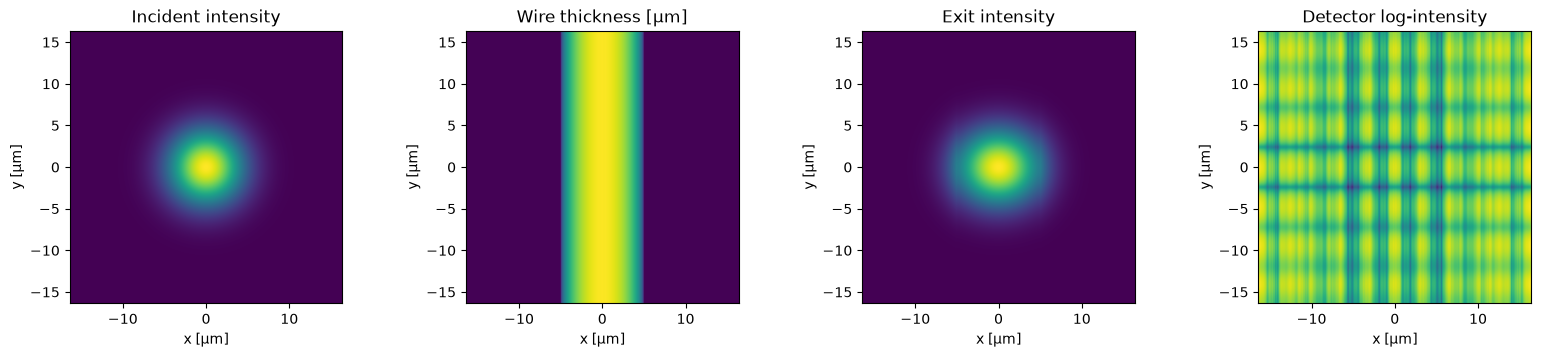

In [6]:
input_grid = result["input_grid"]
detector_grid = result["detector_grid"]
incident_intensity = np.abs(result["incident_field"]) ** 2
exit_intensity = np.abs(result["exit_field"]) ** 2
detector_intensity = np.abs(result["detector_field"]) ** 2

input_extent = np.array([
    input_grid.axis_m[0], input_grid.axis_m[-1],
    input_grid.axis_m[0], input_grid.axis_m[-1],
]) / um
detector_extent = np.array([
    detector_grid.axis_m[0], detector_grid.axis_m[-1],
    detector_grid.axis_m[0], detector_grid.axis_m[-1],
]) / um

fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
axes[0].imshow(incident_intensity, extent=input_extent, origin="lower")
axes[0].set_title("Incident intensity")
axes[1].imshow(result["thickness_m"] / um, extent=input_extent, origin="lower")
axes[1].set_title("Wire thickness [µm]")
axes[2].imshow(exit_intensity, extent=input_extent, origin="lower")
axes[2].set_title("Exit intensity")
axes[3].imshow(
    np.log10(detector_intensity + detector_intensity.max() * 1e-8),
    extent=detector_extent, origin="lower"
)
axes[3].set_title("Detector log-intensity")
for ax in axes:
    ax.set_xlabel("x [µm]")
    ax.set_ylabel("y [µm]")
plt.tight_layout()
plt.show()

## 5. Wire-offset scan: −10 µm to +10 µm

For each wire offset, the 7.5 µm divergent `PCI.py` beam remains centered and the 20 nm voxel-projected wire moves in x. Target-exit intensity is integrated over the two half-planes, with the x = 0 samples divided equally, and each side is normalized by the total incident intensity integrated over the full target plane before the wire. The retained SAXS comparison remains the 7.5 µm `DivSAXS_asymmetry_Mark1300_7p5um.dat` result; its $|q_x| < 0.10$ nm$^{-1}$ exclusion applies to SAXS only.

Rayleigh [m]:  0.0821356996685882
Radius [um]:  276985.09264019405 0.15120024068359483
the beam waist on the target plane is  6.370 um
the FWHM beam waist on the target plane is  7.500 um
the target postion is 0.250 m
complex q parameter is (249999999.99999997+82135699.66858822j)


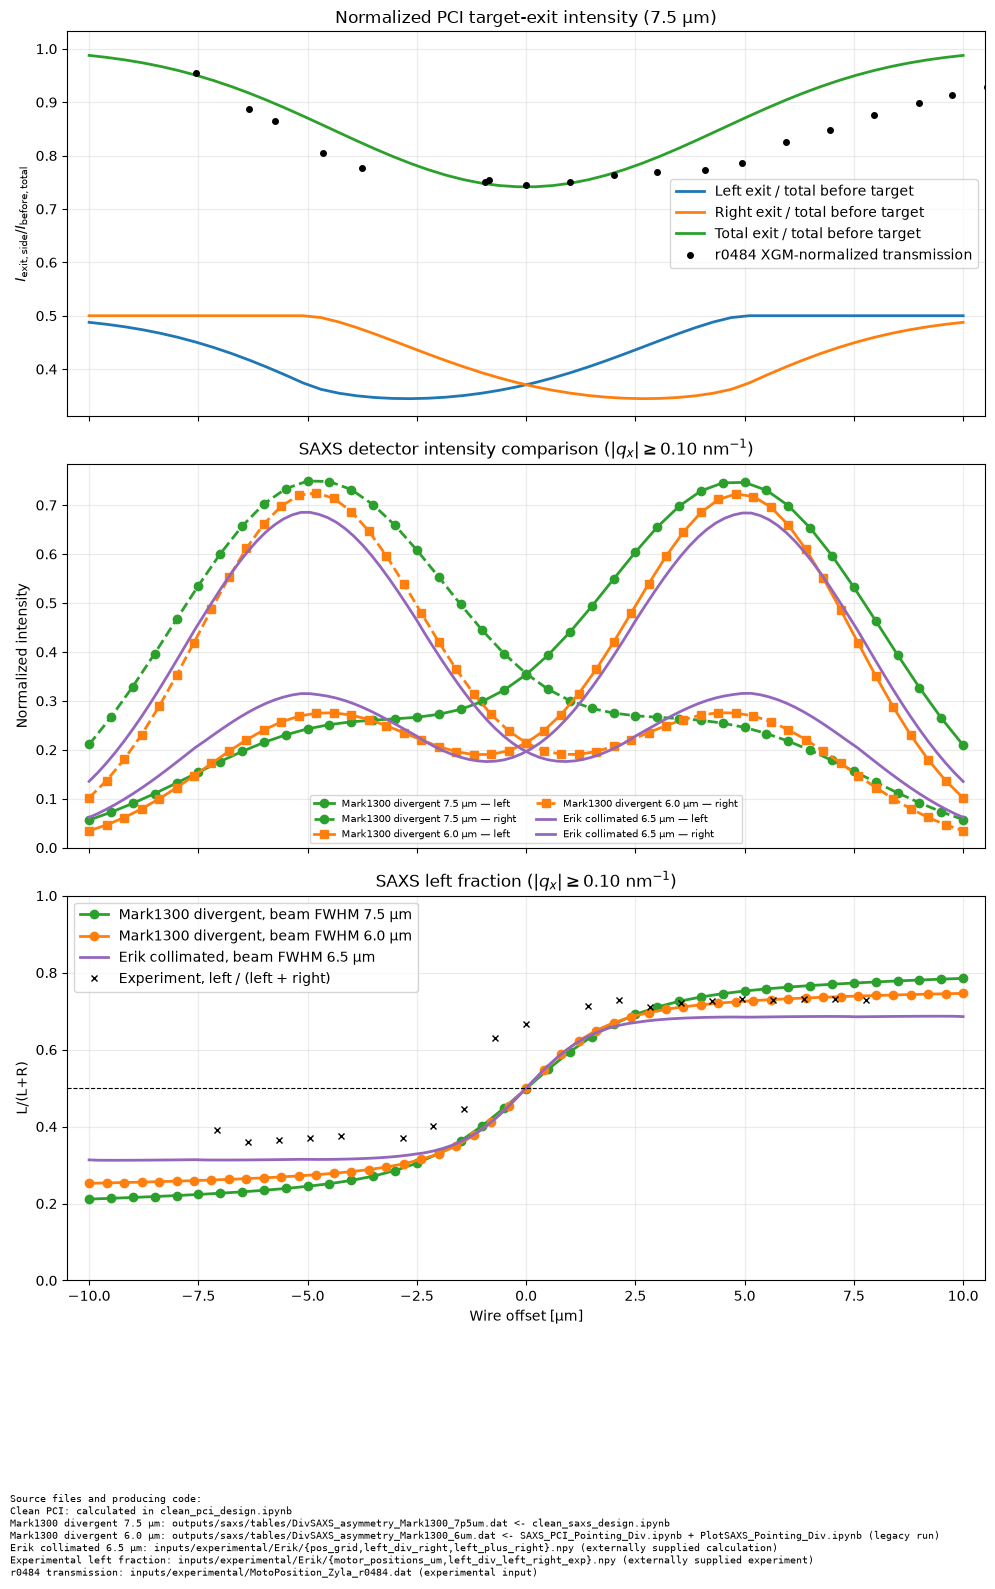

Saved left/right plot: c:\Users\feng48\Downloads\PCI_Codebase\PCI_Codebase\SAXS_asymmetry\outputs\clean_pci\clean_pci_saxs_mark1300_left_right_vs_offset.png
Saved left/right table: c:\Users\feng48\Downloads\PCI_Codebase\PCI_Codebase\SAXS_asymmetry\outputs\clean_pci\clean_pci_exit_left_right_raw_vs_offset.dat
Saved normalized left/right table: c:\Users\feng48\Downloads\PCI_Codebase\PCI_Codebase\SAXS_asymmetry\outputs\clean_pci\pci_exit_left_right_vs_offset.dat
Loaded SAXS detector table: c:\Users\feng48\Downloads\PCI_Codebase\PCI_Codebase\SAXS_asymmetry\outputs\saxs\tables\DivSAXS_asymmetry_Mark1300_7p5um.dat
Loaded 6 µm SAXS detector table: c:\Users\feng48\Downloads\PCI_Codebase\PCI_Codebase\SAXS_asymmetry\outputs\saxs\tables\DivSAXS_asymmetry_Mark1300_6um.dat
Loaded Methods 6 µm table: c:\Users\feng48\Downloads\PCI_Codebase\PCI_Codebase\SAXS_asymmetry\outputs\methods\tables\DivSAXS_asymmetry_Methods_6um.dat
Loaded Methods 7.5 µm table: c:\Users\feng48\Downloads\PCI_Codebase\PCI_Codeba

In [15]:
def scan_exit_side_intensities(config, wire_offsets_m):
    grid = Grid2D(config.n, config.input_pixel_size_m)
    xray = XRay(config.energy_kev)
    source_waist_m = source_waist_from_target_fwhm(
        config.beam_fwhm_m, xray.wavelength_m, config.source_to_sample_position_m
    )
    _, incident_field = pci_py_gaussian_field(
        grid, xray, source_waist_m, config.source_to_sample_position_m
    )
    incident_intensity = np.abs(incident_field)**2
    total_before_target_intensity = incident_intensity.sum()
    center_index = config.n // 2
    incident_lineout = incident_intensity[center_index, :]
    # The Gaussian is separable and wire thickness is y-independent, so
    # this factor restores the exact 2-D half-plane sum and absolute scale.
    y_integral_factor = (
        incident_intensity[:, center_index].sum()
        / incident_intensity[center_index, center_index]
    )
    del incident_field, incident_intensity
    axis_m = grid.axis_m
    left_weights = (axis_m < 0).astype(float)
    right_weights = (axis_m > 0).astype(float)
    center = np.isclose(axis_m, 0.0, rtol=0.0, atol=config.input_pixel_size_m / 2)
    left_weights[center] = 0.5 
    right_weights[center] = 0.5

    left_exit_intensity = np.empty(len(wire_offsets_m), dtype=float)   
    right_exit_intensity = np.empty(len(wire_offsets_m), dtype=float)
    for index, wire_offset_m in enumerate(wire_offsets_m):
        thickness_m = voxelized_wire_lineout(
            grid, config.wire_radius_m, center_x_m=wire_offset_m,
            voxel_size_m=config.wire_voxel_size_m,
            voxel_number=config.wire_voxel_number,
        )
        exit_lineout = incident_lineout * np.exp(
            -thickness_m / config.copper_attenuation_length_m
        )
        left_exit_intensity[index] = y_integral_factor * np.sum(
            exit_lineout * left_weights
        )
        right_exit_intensity[index] = y_integral_factor * np.sum(
            exit_lineout * right_weights
        )

    return left_exit_intensity, right_exit_intensity, total_before_target_intensity


offsets_um = np.linspace(-10.0, 10.0, 50)
left_exit_intensity, right_exit_intensity, total_before_target_intensity = (
    scan_exit_side_intensities(
    PCIConfig(), offsets_um * um
    )
)
total_exit_intensity = left_exit_intensity + right_exit_intensity
left_exit_fraction = left_exit_intensity / total_before_target_intensity
right_exit_fraction = right_exit_intensity / total_before_target_intensity
total_exit_fraction = total_exit_intensity / total_before_target_intensity

saxs_table_path = OUTPUT_DIR / "saxs" / "tables" / "DivSAXS_asymmetry_Mark1300_7p5um.dat"
saxs_scan = np.loadtxt(saxs_table_path)
saxs_offsets_um = saxs_scan[:, 0] / 1e3  # legacy table stores offset in nm
saxs_mark1300_left_intensity = saxs_scan[:, 1]
saxs_mark1300_right_intensity = saxs_scan[:, 2]
saxs_mark1300_left_fraction = (
    saxs_mark1300_left_intensity
    / (saxs_mark1300_left_intensity + saxs_mark1300_right_intensity)
)

saxs_6um_table_path = OUTPUT_DIR / "saxs" / "tables" / "DivSAXS_asymmetry_Mark1300_6um.dat"
saxs_6um_scan = np.loadtxt(saxs_6um_table_path)
saxs_6um_offsets_um = saxs_6um_scan[:, 0] / 1e3
saxs_6um_left_intensity = saxs_6um_scan[:, 1]
saxs_6um_right_intensity = saxs_6um_scan[:, 2]
saxs_6um_left_fraction = (
    saxs_6um_left_intensity / (saxs_6um_left_intensity + saxs_6um_right_intensity)
)
saxs_6um_intensity_scale = np.nanmax(
    saxs_6um_left_intensity + saxs_6um_right_intensity
)

methods_6um_path = OUTPUT_DIR / "methods" / "tables" / "DivSAXS_asymmetry_Methods_6um.dat"
methods_6um_scan = np.loadtxt(methods_6um_path)
methods_6um_offsets_um = methods_6um_scan[:, 0] / 1e3
methods_6um_left_intensity = methods_6um_scan[:, 1]
methods_6um_right_intensity = methods_6um_scan[:, 2]
methods_6um_intensity_scale = np.nanmax(
    methods_6um_left_intensity + methods_6um_right_intensity
)

methods_7p5um_path = OUTPUT_DIR / "methods" / "tables" / "DivSAXS_asymmetry_Methods_7p5um.dat"
methods_7p5um_scan = np.loadtxt(methods_7p5um_path)
methods_7p5um_offsets_um = methods_7p5um_scan[:, 0] / 1e3
methods_7p5um_left_intensity = methods_7p5um_scan[:, 1]
methods_7p5um_right_intensity = methods_7p5um_scan[:, 2]
methods_7p5um_intensity_scale = np.nanmax(
    methods_7p5um_left_intensity + methods_7p5um_right_intensity
)

erik_dir = INPUT_DIR / "experimental" / "Erik"
erik_positions_um = np.load(erik_dir / "pos_grid.npy").astype(float) / 1e3
erik_left_over_right = np.load(erik_dir / "left_div_right.npy").astype(float)
erik_total_intensity = np.load(erik_dir / "left_plus_right.npy").astype(float)
if not (erik_positions_um.shape == erik_left_over_right.shape == erik_total_intensity.shape):
    raise ValueError("Erik position, L/R, and L+R arrays must have matching shapes.")
erik_right_intensity = erik_total_intensity / (1 + erik_left_over_right)
erik_left_intensity = erik_left_over_right * erik_right_intensity
erik_left_fraction = erik_left_intensity / erik_total_intensity
exp_motor_positions_um = np.load(erik_dir / "motor_positions_um.npy").astype(float)
exp_left_frac = np.load(erik_dir / "left_div_left_right_exp.npy").astype(float)
if exp_motor_positions_um.shape != exp_left_frac.shape:
    raise ValueError("Experimental motor-position and left-fraction arrays must match.")
saxs_mark1300_intensity_scale = np.nanmax(
    saxs_mark1300_left_intensity + saxs_mark1300_right_intensity
)
erik_intensity_scale = np.nanmax(erik_total_intensity)

transmission_path = INPUT_DIR / "experimental" / "MotoPosition_Zyla_r0484.dat"
transmission_data = np.loadtxt(transmission_path)
if transmission_data.shape[0] != 3 and transmission_data.shape[1] == 3:
    transmission_data = transmission_data.T
if transmission_data.shape[0] != 3:
    raise ValueError("MotoPosition_Zyla_r0484.dat must contain three rows.")
transmission_position_raw = transmission_data[0].astype(float)
transmission_xgm = transmission_data[2].astype(float)
exp_minimum = int(np.nanargmin(transmission_xgm))
exp_transmission_position_um = (
    transmission_position_raw - transmission_position_raw[exp_minimum]
) * 1e3
exp_transmission = transmission_xgm / np.nanmax(transmission_xgm)

fig, axes = plt.subplots(3, 1, figsize=(10, 16), sharex=True)
ax = axes[0]
ax.plot(
    offsets_um, left_exit_fraction, color="tab:blue", linewidth=2,
    label=r"Left exit / total before target",
)
ax.plot(
    offsets_um, right_exit_fraction, color="tab:orange", linewidth=2,
    label=r"Right exit / total before target",
)
ax.plot(
    offsets_um, total_exit_fraction, color="tab:green", linewidth=2,
    label=r"Total exit / total before target",
)
ax.plot(
    exp_transmission_position_um, exp_transmission, "ko", ms=4,
    label="r0484 XGM-normalized transmission",
)
ax.set(
    ylabel=r"$I_{\mathrm{exit,side}}/I_{\mathrm{before,total}}$",
    title="Normalized PCI target-exit intensity (7.5 µm)",
    xlim=(-10.5, 10.5),
)

ax.legend()

axes[1].plot(
    saxs_offsets_um, saxs_mark1300_left_intensity / saxs_mark1300_intensity_scale, "o-",
    color="tab:green", linewidth=2, label="Mark1300 divergent 7.5 µm — left",
)
axes[1].plot(
    saxs_offsets_um, saxs_mark1300_right_intensity / saxs_mark1300_intensity_scale, "o--",
    color="tab:green", linewidth=2, label="Mark1300 divergent 7.5 µm — right",
)
axes[1].plot(
    saxs_6um_offsets_um, saxs_6um_left_intensity / saxs_6um_intensity_scale, "s-",
    color="tab:orange", linewidth=2, label="Mark1300 divergent 6.0 µm — left",
)
axes[1].plot(
    saxs_6um_offsets_um, saxs_6um_right_intensity / saxs_6um_intensity_scale, "s--",
    color="tab:orange", linewidth=2, label="Mark1300 divergent 6.0 µm — right",
)
# axes[1].plot(
#     methods_7p5um_offsets_um,
#     methods_7p5um_left_intensity / methods_7p5um_intensity_scale, "^-",
#     color="tab:green", linewidth=2, label="Methods divergent 7.5 µm — left",
# )
# axes[1].plot(
#     methods_7p5um_offsets_um,
#     methods_7p5um_right_intensity / methods_7p5um_intensity_scale, "^--",
#     color="tab:green", linewidth=2, label="Methods divergent 7.5 µm — right",
# )
# axes[1].plot(
#     methods_6um_offsets_um, methods_6um_left_intensity / methods_6um_intensity_scale, "D-",
#     color="tab:red", linewidth=2, label="Methods divergent 6.0 µm — left",
# )
# axes[1].plot(
#     methods_6um_offsets_um, methods_6um_right_intensity / methods_6um_intensity_scale, "D--",
#     color="tab:red", linewidth=2, label="Methods divergent 6.0 µm — right",
#)
axes[1].plot(
    erik_positions_um, erik_left_intensity / erik_intensity_scale, "-",
    color="tab:purple", linewidth=2, label="Erik collimated 6.5 µm — left",
)
axes[1].plot(
    erik_positions_um, erik_right_intensity / erik_intensity_scale, "-",
    color="tab:purple", linewidth=2, label="Erik collimated 6.5 µm — right",
)
axes[1].set(
    ylabel="Normalized intensity",
    title=r"SAXS detector intensity comparison ($|q_x| \geq 0.10$ nm$^{-1}$)",
)
axes[1].legend(fontsize=7, ncol=2)

axes[2].plot(
    saxs_offsets_um, saxs_mark1300_left_fraction, "o-",
    color="tab:green", linewidth=2,
    label="Mark1300 divergent, beam FWHM 7.5 µm",
)
axes[2].plot(
    saxs_6um_offsets_um, saxs_6um_left_fraction, "o-",
    color="tab:orange", linewidth=2,
    label="Mark1300 divergent, beam FWHM 6.0 µm",
)
axes[2].plot(
    erik_positions_um, erik_left_fraction, "-",
    color="tab:purple", linewidth=2,
    label="Erik collimated, beam FWHM 6.5 µm",
)
axes[2].plot(
    exp_motor_positions_um, exp_left_frac, "kx", ms=5,
    label="Experiment, left / (left + right)",
)
axes[2].axhline(0.5, color="k", linewidth=0.8, linestyle="--")
axes[2].set(
    xlabel="Wire offset [µm]", ylabel="L/(L+R)",
    title=r"SAXS left fraction ($|q_x| \geq 0.10$ nm$^{-1}$)",
    ylim=(0, 1),
)
axes[2].legend()
for axis in axes:
    axis.grid(alpha=0.25)

provenance_text = (
    "Source files and producing code:\n"
    "Clean PCI: calculated in clean_pci_design.ipynb\n"
    "Mark1300 divergent 7.5 µm: outputs/saxs/tables/DivSAXS_asymmetry_Mark1300_7p5um.dat"
    " <- clean_saxs_design.ipynb\n"
    "Mark1300 divergent 6.0 µm: outputs/saxs/tables/DivSAXS_asymmetry_Mark1300_6um.dat"
    " <- SAXS_PCI_Pointing_Div.ipynb + PlotSAXS_Pointing_Div.ipynb (legacy run)\n"
    "Erik collimated 6.5 µm: inputs/experimental/Erik/{pos_grid,left_div_right,left_plus_right}.npy"
    " (externally supplied calculation)\n"
    "Experimental left fraction: inputs/experimental/Erik/{motor_positions_um,left_div_left_right_exp}.npy"
    " (externally supplied experiment)\n"
    "r0484 transmission: inputs/experimental/MotoPosition_Zyla_r0484.dat (experimental input)"
)
fig.text(
    0.01, 0.01, provenance_text, ha="left", va="bottom",
    fontsize=7, family="monospace",
)
fig.tight_layout(rect=(0, 0.16, 1, 1))
side_figure_path = CLEAN_PCI_OUTPUT_DIR / "clean_pci_saxs_mark1300_left_right_vs_offset.png"
fig.savefig(side_figure_path, dpi=200, bbox_inches="tight")
plt.show()

side_table_path = CLEAN_PCI_OUTPUT_DIR / "clean_pci_exit_left_right_raw_vs_offset.dat"
np.savetxt(
    side_table_path,
    np.column_stack((offsets_um, left_exit_intensity, right_exit_intensity, total_exit_intensity)),
    header="offset_um raw_left_exit_intensity_au raw_right_exit_intensity_au raw_total_exit_intensity_au",
)
normalized_side_table_path = CLEAN_PCI_OUTPUT_DIR / "pci_exit_left_right_vs_offset.dat"
np.savetxt(
    normalized_side_table_path,
    np.column_stack((offsets_um, left_exit_fraction, right_exit_fraction, total_exit_fraction)),
    header="offset_um left_exit_over_total_before right_exit_over_total_before total_exit_over_total_before",
)
print(f"Saved left/right plot: {side_figure_path}")
print(f"Saved left/right table: {side_table_path}")
print(f"Saved normalized left/right table: {normalized_side_table_path}")
print(f"Loaded SAXS detector table: {saxs_table_path}")
print(f"Loaded 6 µm SAXS detector table: {saxs_6um_table_path}")
print(f"Loaded Methods 6 µm table: {methods_6um_path}")
print(f"Loaded Methods 7.5 µm table: {methods_7p5um_path}")
print(f"Loaded Erik comparison arrays: {erik_dir}")
print(f"Loaded experimental transmission: {transmission_path}")
print(f"Total before-target intensity: {total_before_target_intensity:.6f}")
print(f"Normalized PCI total-exit range: {total_exit_fraction.min():.6f} to {total_exit_fraction.max():.6f}")

## 6. Save detector data as TIFF

In [8]:
detector_tif_path = CLEAN_PCI_OUTPUT_DIR / "clean_pci_detector_intensity.tif"
detector_tif_data = detector_intensity.astype(np.float32)
Image.fromarray(detector_tif_data).save(
    detector_tif_path, format="TIFF", compression="tiff_deflate"
)
print(f"Saved detector intensity: {detector_tif_path.resolve()}")
print(f"TIFF shape: {detector_tif_data.shape}, dtype: {detector_tif_data.dtype}")

Saved detector intensity: C:\Users\feng48\Downloads\PCI_Codebase\PCI_Codebase\SAXS_asymmetry\outputs\clean_pci\clean_pci_detector_intensity.tif
TIFF shape: (4096, 4096), dtype: float32
